# House Prices: models and predictions

This notebook compares our models, tunes Ridge and XGBoost, looks at the largest prediction errors, and creates the final CatBoost submission. The cleaning and encoding rules come from `01_EDA.ipynb`.

## 1. Setup and baseline (C1)

### Load the preprocessing pipeline

We read only the cell tagged `house-prices-pipeline` from `01_EDA.ipynb`. This gives us `make_model_pipeline(model)` without running the EDA, plots, or CSV exports again. In Colab, the saved EDA notebook needs to be available at `/content/01_EDA.ipynb`.

Each pipeline fit learns its own cleaning statistics and encoders from the training rows. Our outlier rule is applied to those training rows only; validation rows are always kept.

In [1]:
import json
from pathlib import Path

eda_path = Path("/content/01_EDA.ipynb")

with eda_path.open(encoding="utf-8") as f:
    notebook = json.load(f)

pipeline_cells = [
    cell for cell in notebook["cells"]
    if cell["cell_type"] == "code"
    and "house-prices-pipeline" in cell.get("metadata", {}).get("tags", [])
]

if len(pipeline_cells) != 1:
    raise ValueError("Expected exactly one tagged pipeline cell.")

code = "".join(pipeline_cells[0]["source"])
exec(compile(code, str(eda_path), "exec"), globals())

### Install CatBoost

CatBoost is an extra library, so we install it before the model comparisons. The other imports are kept with the code that uses them.

In [2]:
%pip install -q catboost

### Raw data, log target, and five folds

For CV we start with raw `train.csv`, not the processed exports. `y` is `np.log(SalePrice)`, calculated **once** here. The pipeline expects that logged target and does not log it again.

We use five shuffled folds with `random_state=42`. Every model uses the same splits, so the comparisons are consistent. The mean baseline predicts the average log-price of its training fold. Scikit-learn returns negative RMSE scores, so the minus sign converts them back to positive errors. Lower is better.

In [3]:
import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score

raw_train = pd.read_csv("/content/train.csv")

X = raw_train.drop(columns="SalePrice")
y = np.log(raw_train["SalePrice"])  # log once here!!!!!!!

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Predicts the mean log(SalePrice) learned from each training fold.
baseline = make_model_pipeline(DummyRegressor(strategy="mean"))

fold_rmse = -cross_val_score(
    baseline,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    error_score="raise",
)

for fold, rmse in enumerate(fold_rmse, start=1):
    print(f"Fold {fold}: RMSE = {rmse:.5f}")

print(f"\nMean RMSE: {fold_rmse.mean():.5f}")
print(f"Std RMSE:  {fold_rmse.std():.5f}")

Fold 1: RMSE = 0.43324
Fold 2: RMSE = 0.39585
Fold 3: RMSE = 0.37537
Fold 4: RMSE = 0.42101
Fold 5: RMSE = 0.36846

Mean RMSE: 0.39878
Std RMSE:  0.02513


The baseline mean RMSE is **0.39878**. It does not distinguish between houses, so our models should improve on this by using their features.

## 2. Comparing the initial models (C2)

### Ridge

Ridge is our linear model. We start with `alpha=1`; tuning comes later. `StandardScaler` sits inside the model pipeline because Ridge's penalty depends on feature scale. The scaler is fitted separately within each training fold, after cleaning and encoding.

In [4]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, GridSearchCV

ridge_pipeline = make_model_pipeline(
    Pipeline([
        ("scale", StandardScaler()),
        ("ridge", Ridge(alpha=1.0)),
    ])
)

ridge_rmse = -cross_val_score(
    ridge_pipeline,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    error_score="raise",
)

for fold, rmse in enumerate(ridge_rmse, start=1):
    print(f"Fold {fold}: RMSE = {rmse:.5f}")

print(f"\nRidge mean RMSE: {ridge_rmse.mean():.5f}")
print(f"Ridge std RMSE:  {ridge_rmse.std():.5f}")

Fold 1: RMSE = 0.12431
Fold 2: RMSE = 0.12303
Fold 3: RMSE = 0.22534
Fold 4: RMSE = 0.12079
Fold 5: RMSE = 0.11141

Ridge mean RMSE: 0.14098
Ridge std RMSE:  0.04242


### Random Forest

Random Forest averages many decision trees and can capture nonlinear relationships between the features and price. We use 300 trees and a fixed random seed. Scaling is not needed for this model.

In [5]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = make_model_pipeline(
    RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )
)

rf_rmse = -cross_val_score(
    rf_pipeline,
    X,
    y,  # alr logged
    cv=cv,
    scoring="neg_root_mean_squared_error",
    error_score="raise",
)

for fold, rmse in enumerate(rf_rmse, start=1):
    print(f"Fold {fold}: RMSE = {rmse:.5f}")

print(f"\nRandom Forest mean RMSE: {rf_rmse.mean():.5f}")
print(f"Random Forest std RMSE:  {rf_rmse.std():.5f}")

Fold 1: RMSE = 0.14484
Fold 2: RMSE = 0.12470
Fold 3: RMSE = 0.17259
Fold 4: RMSE = 0.14325
Fold 5: RMSE = 0.12187

Random Forest mean RMSE: 0.14145
Random Forest std RMSE:  0.01816


### XGBoost

XGBoost builds trees in sequence, with later trees correcting earlier errors. This first version uses 300 trees, a learning rate of 0.05, and depth 3. We keep the same raw inputs, logged target, and CV splits.

In [6]:
from xgboost import XGBRegressor

xgb_pipeline = make_model_pipeline(
    XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=2,
    )
)

xgb_rmse = -cross_val_score(
    xgb_pipeline,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    error_score="raise",
)

for fold, rmse in enumerate(xgb_rmse, start=1):
    print(f"Fold {fold}: RMSE = {rmse:.5f}")

print(f"\nXGBoost mean RMSE: {xgb_rmse.mean():.5f}")
print(f"XGBoost std RMSE:  {xgb_rmse.std():.5f}")

Fold 1: RMSE = 0.12787
Fold 2: RMSE = 0.11334
Fold 3: RMSE = 0.16759
Fold 4: RMSE = 0.12392
Fold 5: RMSE = 0.11353

XGBoost mean RMSE: 0.12925
XGBoost std RMSE:  0.02000


### CatBoost

We also try CatBoost with 1000 iterations, a learning rate of 0.05, and depth 5. This version uses the same encoded features as the other models; it does not use CatBoost's native categorical handling. No extra scaling or target transformation is applied.

In [7]:
from catboost import CatBoostRegressor

cat_pipeline = make_model_pipeline(
    CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=5,
        loss_function="RMSE",
        random_seed=42,
        thread_count=2,
        verbose=False,
        allow_writing_files=False,
    )
)

cat_rmse = -cross_val_score(
    cat_pipeline,
    X,
    y,  # Already log(SalePrice).
    cv=cv,
    scoring="neg_root_mean_squared_error",
    error_score="raise",
)

for fold, rmse in enumerate(cat_rmse, start=1):
    print(f"Fold {fold}: RMSE = {rmse:.5f}")

print(f"\nCatBoost mean RMSE: {cat_rmse.mean():.5f}")
print(f"CatBoost std RMSE:  {cat_rmse.std():.5f}")

Fold 1: RMSE = 0.12371
Fold 2: RMSE = 0.10776
Fold 3: RMSE = 0.15302
Fold 4: RMSE = 0.11899
Fold 5: RMSE = 0.10534

CatBoost mean RMSE: 0.12176
CatBoost std RMSE:  0.01705


## 3. Hyperparameter tuning (C3)

Both searches evaluate the full preprocessing pipeline with the same five folds. `refit=True` also fits the selected pipeline on all training data after the search.

The best score is a **tuning CV score**, since those folds were used to choose the parameters. It can be optimistic compared with a separate evaluation.

### Ridge: strength of regularization

We search nine values of `alpha`, which controls how strongly the coefficients are shrunk. `model__ridge__alpha` reaches the Ridge estimator inside the nested pipeline.

In [8]:
param_grid = {
    "model__ridge__alpha": [
        0.01, 0.1, 1, 10, 30, 100, 300, 1000, 3000
    ]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise",
)

ridge_search.fit(X, y)

print("Best alpha:", ridge_search.best_params_["model__ridge__alpha"])
print(f"Best tuning CV RMSE: {-ridge_search.best_score_:.5f}")

# Already refitted on all training data using the best alpha.
best_ridge = ridge_search.best_estimator_

Best alpha: 300
Best tuning CV RMSE: 0.13451


The selected value is **alpha = 300**, with a tuning CV RMSE of **0.13452**, compared with **0.14098** for the initial Ridge model.

### XGBoost: number of trees, depth, and learning rate

The grid contains 18 combinations, each evaluated on five folds: 90 CV fits in total. Cleaning and encoding are fitted again within each training fold for every candidate.

In [9]:
xgb_param_grid = {
    "model__n_estimators": [300, 600, 1000],
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.03, 0.05],
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1,
    error_score="raise",
)

xgb_search.fit(X, y)

print("Best parameters:", xgb_search.best_params_)
print(f"Best tuning CV RMSE: {-xgb_search.best_score_:.5f}")

# Already refitted on all training data with the best parameters.
best_xgb = xgb_search.best_estimator_

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 1000}
Best tuning CV RMSE: 0.12712


The selected settings are **1000 trees, depth 3, and learning rate 0.05**. The tuning CV RMSE is **0.12695**, a small improvement over the initial **0.12881**.

## 4. Ensemble experiment and model comparison (C4)

### CatBoost + XGBoost

We try an equal-weight average of CatBoost and XGBoost with the selected XGBoost settings. Both models use the same preprocessing fitted within each training fold. Their predictions are averaged in log-price space.

In [10]:
from sklearn.ensemble import VotingRegressor

ensemble_pipeline = make_model_pipeline(
    VotingRegressor(
        estimators=[
            ("catboost", CatBoostRegressor(
                iterations=1000,
                learning_rate=0.05,
                depth=5,
                loss_function="RMSE",
                random_seed=42,
                thread_count=2,
                verbose=False,
                allow_writing_files=False,
            )),
            ("xgboost", XGBRegressor(
                objective="reg:squarederror",
                tree_method="hist",
                n_estimators=1000,
                learning_rate=0.05,
                max_depth=3,
                random_state=42,
                n_jobs=2,
            )),
        ],
        weights=[1, 1],
        n_jobs=1,
    )
)

ensemble_rmse = -cross_val_score(
    ensemble_pipeline,
    X,
    y,  # Already logged—no additional log.
    cv=cv,
    scoring="neg_root_mean_squared_error",
    error_score="raise",
)

for fold, rmse in enumerate(ensemble_rmse, start=1):
    print(f"Fold {fold}: RMSE = {rmse:.5f}")

print(f"\nEnsemble mean RMSE: {ensemble_rmse.mean():.5f}")
print(f"Ensemble std RMSE:  {ensemble_rmse.std():.5f}")

Fold 1: RMSE = 0.12417
Fold 2: RMSE = 0.10787
Fold 3: RMSE = 0.15734
Fold 4: RMSE = 0.11629
Fold 5: RMSE = 0.10553

Ensemble mean RMSE: 0.12224
Ensemble std RMSE:  0.01874


## 5. Error analysis (C5)

### A closer look at fold 3

Fold 3 has a larger error across several models. We refit a fresh copy of the CatBoost pipeline on that fold's training rows and inspect predictions for its validation rows only.

`LogResidual` is actual minus predicted log-price: positive means underprediction, negative means overprediction. `ErrorShare_pct` shows how much each house contributes to the fold's total squared error.

In [11]:
from sklearn.base import clone

# Recreate exactly the same splits.
splits = list(cv.split(X, y))
train_idx, valid_idx = splits[2]  # Fold 3: Python counts from zero.

fold3_model = clone(cat_pipeline)
fold3_model.fit(X.iloc[train_idx], y.iloc[train_idx])

pred_log = fold3_model.predict(X.iloc[valid_idx])
actual_log = y.iloc[valid_idx].to_numpy()

# Keep raw features so we can inspect the houses.
fold3_errors = X.iloc[valid_idx].copy()
fold3_errors["ActualPrice"] = np.exp(actual_log)
fold3_errors["PredictedPrice"] = np.exp(pred_log)
fold3_errors["LogResidual"] = actual_log - pred_log
fold3_errors["SquaredLogError"] = (actual_log - pred_log) ** 2

# Contribution to this fold's total squared error.
fold3_errors["ErrorShare_pct"] = (
    100
    * fold3_errors["SquaredLogError"]
    / fold3_errors["SquaredLogError"].sum()
)

fold3_errors = fold3_errors.sort_values(
    "SquaredLogError", ascending=False
)

print(f"Fold 3 RMSE: {np.sqrt(np.mean((actual_log - pred_log)**2)):.5f}")
print(
    "Top 5 houses contribute "
    f"{fold3_errors['ErrorShare_pct'].head(5).sum():.1f}% "
    "of this fold's squared error."
)

display(
    fold3_errors[[
        "Id", "ActualPrice", "PredictedPrice",
        "LogResidual", "ErrorShare_pct",
        "GrLivArea", "OverallQual", "TotalBsmtSF",
        "YearBuilt", "Neighborhood", "SaleCondition",
    ]].head(15).round(3)
)

Fold 3 RMSE: 0.15302
Top 5 houses contribute 60.7% of this fold's squared error.


,Id,ActualPrice,PredictedPrice,LogResidual,ErrorShare_pct,GrLivArea,OverallQual,TotalBsmtSF,YearBuilt,Neighborhood,SaleCondition
523,524,184750.0,678310.183,-1.301,24.742,4676,10,3138,2007,Edwards,Partial
1298,1299,160000.0,566735.933,-1.265,23.395,5642,10,6110,2008,Edwards,Partial
1324,1325,147000.0,286855.968,-0.669,6.537,1795,8,1795,2006,Somerst,Partial
970,971,135000.0,83214.338,0.484,3.424,1192,4,720,1949,NAmes,Abnorml
1453,1454,84500.0,128824.500,-0.422,2.601,1140,5,1140,2006,Mitchel,Abnorml
533,534,39300.0,55902.876,-0.352,1.816,334,1,0,1946,BrkSide,Normal
66,67,180000.0,248102.787,-0.321,1.506,2207,7,1947,1970,NAmes,Normal
142,143,166000.0,122012.076,0.308,1.386,1385,5,910,1952,NAmes,Normal
1383,1384,112000.0,150948.583,-0.298,1.303,1416,5,816,1918,Sawyer,Normal
1022,1023,87000.0,115785.165,-0.286,1.195,1248,5,912,1930,OldTown,Normal


### Where does the error come from?

The largest contributors are **Ids 524 and 1299**, the same unusually large, low-price houses discussed in the EDA.

These two houses are excluded when they are in a training fold, but they remain in validation. Both land in fold 3, where CatBoost overpredicts their prices. This explains much of that fold's higher error. We keep them in the validation score.

The left plot compares actual and predicted log-prices; points on the dashed line are exact predictions. The right plot shows the ten largest error contributions.

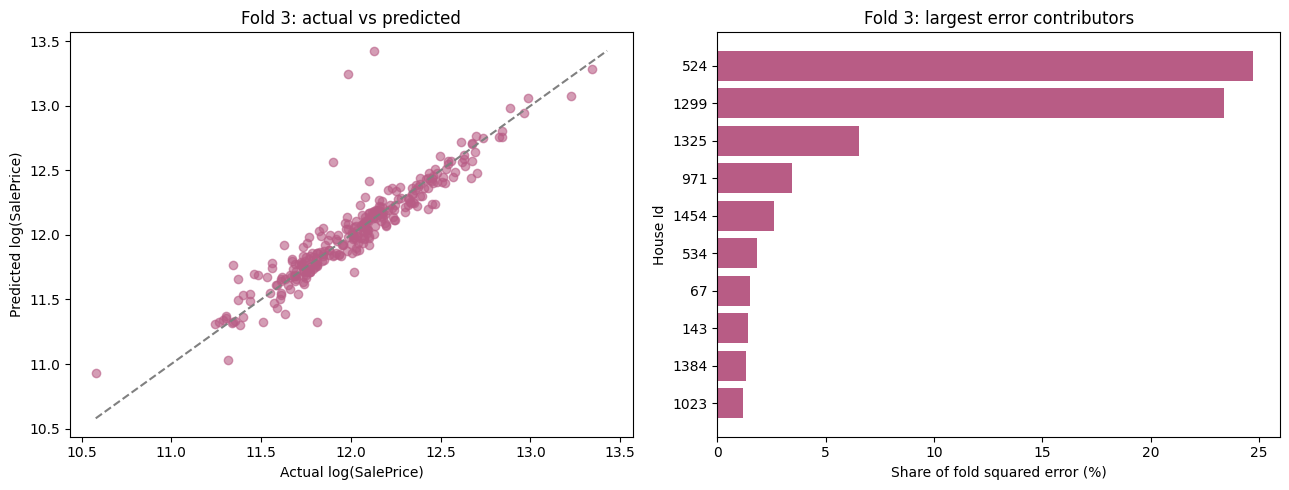

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(actual_log, pred_log, alpha=0.6, color="#B85C85")
limits = [
    min(actual_log.min(), pred_log.min()),
    max(actual_log.max(), pred_log.max()),
]
axes[0].plot(limits, limits, "--", color="gray")
axes[0].set(
    xlabel="Actual log(SalePrice)",
    ylabel="Predicted log(SalePrice)",
    title="Fold 3: actual vs predicted",
)

top = fold3_errors.head(10)
axes[1].barh(
    top["Id"].astype(str).iloc[::-1],
    top["ErrorShare_pct"].iloc[::-1],
    color="#B85C85",
)
axes[1].set(
    xlabel="Share of fold squared error (%)",
    ylabel="House Id",
    title="Fold 3: largest error contributors",
)

plt.tight_layout()
plt.show()

### Would keeping outliers in training help? Totally optional to look at btw just curiosity

We repeat CV with a standard `Pipeline`, which keeps the same cleaning, encoding, and CatBoost steps but skips our training-only row removal. The validation folds stay the same.

In [13]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

cat_keep_outliers = Pipeline([
    (name, clone(step))
    for name, step in cat_pipeline.steps
])

keep_rmse = -cross_val_score(
    cat_keep_outliers,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    error_score="raise",
)

print(f"Mean RMSE: {keep_rmse.mean():.5f}")
print(f"Std RMSE:  {keep_rmse.std():.5f}")

pd.DataFrame({
    "Fold": range(1, 6),
    "Remove training outliers": cat_rmse,
    "Keep training outliers": keep_rmse,
})

Mean RMSE: 0.12185
Std RMSE:  0.01698


,Fold,Remove training outliers,Keep training outliers
0,1,0.123710,0.123861
1,2,0.107764,0.109060
2,3,0.153016,0.153016
3,4,0.118990,0.118508
4,5,0.105342,0.104796


Keeping the outliers gives a mean RMSE of **0.12366**, compared with **0.12079** when removing them from training. The difference is small, but there is no improvement in mean RMSE, so we retain the original approach.

Fold 3's result is identical in both experiments because both unusual houses are in validation, not training, for that split.

In [14]:
# Collect the selected grid-search candidate's existing fold scores.
def tuning_fold_scores(search):
    return np.array([
        -search.cv_results_[f"split{i}_test_score"][search.best_index_]
        for i in range(search.n_splits_)
    ])


model_scores = {
    "Mean baseline": fold_rmse,
    "Ridge": ridge_rmse,
    "Random Forest": rf_rmse,
    "XGBoost": xgb_rmse,
    "CatBoost": cat_rmse,
    "Ridge, tuned": tuning_fold_scores(ridge_search),
    "XGBoost, tuned": tuning_fold_scores(xgb_search),
    "CatBoost + XGBoost": ensemble_rmse,
    "CatBoost, keep training outliers": keep_rmse,
}

rows = []

for name, scores in model_scores.items():
    scores = np.asarray(scores)

    row = {
        "model": name,
        "mean_cv_rmse": scores.mean(),
        "std_cv_rmse": scores.std(),
        "evaluation": (
            "Best tuning CV score"
            if name.endswith(", tuned")
            else "CV with fixed settings"
        ),
    }

    for fold, score in enumerate(scores, start=1):
        row[f"fold_{fold}_rmse"] = score

    rows.append(row)

model_comparison = (
    pd.DataFrame(rows)
    .sort_values("mean_cv_rmse")
    .reset_index(drop=True)
)

results_dir = Path("/content/results")
# Later, when running from notebooks/: Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

comparison_path = results_dir / "model_comparison.csv"
model_comparison.to_csv(comparison_path, index=False)

display(model_comparison.round(5))
print(f"Saved to {comparison_path}")

,model,mean_cv_rmse,std_cv_rmse,evaluation,fold_1_rmse,fold_2_rmse,fold_3_rmse,fold_4_rmse,fold_5_rmse
0,CatBoost,0.12176,0.01705,CV with fixed settings,0.12371,0.10776,0.15302,0.11899,0.10534
1,"CatBoost, keep training outliers",0.12185,0.01698,CV with fixed settings,0.12386,0.10906,0.15302,0.11851,0.10480
2,CatBoost + XGBoost,0.12224,0.01874,CV with fixed settings,0.12417,0.10787,0.15734,0.11629,0.10553
3,"XGBoost, tuned",0.12712,0.02043,Best tuning CV score,0.12319,0.11135,0.16680,0.12207,0.11217
4,XGBoost,0.12925,0.02000,CV with fixed settings,0.12787,0.11334,0.16759,0.12392,0.11353
5,"Ridge, tuned",0.13451,0.03723,Best tuning CV score,0.12367,0.11382,0.20825,0.11870,0.10812
6,Ridge,0.14098,0.04242,CV with fixed settings,0.12431,0.12303,0.22534,0.12079,0.11141
7,Random Forest,0.14145,0.01816,CV with fixed settings,0.14484,0.12470,0.17259,0.14325,0.12187
8,Mean baseline,0.39878,0.02513,CV with fixed settings,0.43324,0.39585,0.37537,0.42101,0.36846


Saved to /content/results/model_comparison.csv


## 6. Final fit and submission (C6)

### Use the processed CSVs

Now that the model settings have been selected, we use `train_processed.csv` and `test_processed.csv` exported by the matching EDA notebook. Preprocessing fitted on all training data is appropriate for this final fit; these exports were not used as inputs to CV.

The training export already contains **`SalePrice_log`**, so we use it directly without another log. `Id` is kept for the submission and removed from the model features. We train CatBoost directly because these files are already cleaned and encoded; running the preprocessing pipeline again would process them twice.

Test columns are checked and put in the same order as the training features. Predictions are converted back to dollars with `np.exp`, checked, and saved to `submissions/submission_catboost.csv`.

In [15]:
import numpy as np
import pandas as pd
from pathlib import Path
from catboost import CatBoostRegressor

train_processed = pd.read_csv("/content/train_processed.csv")
test_processed = pd.read_csv("/content/test_processed.csv")

X_final = train_processed.drop(columns=["Id", "SalePrice_log"])
y_final = train_processed["SalePrice_log"]  # Already logged!

test_ids = test_processed["Id"]
X_test_final = test_processed.drop(columns="Id")

# Check feature consistency and match their order.
assert set(X_final.columns) == set(X_test_final.columns)
X_test_final = X_test_final[X_final.columns]

final_catboost = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=5,
    loss_function="RMSE",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False,
)

final_catboost.fit(X_final, y_final)

# Convert predicted log-prices back to dollars.
predictions = np.exp(final_catboost.predict(X_test_final))

assert np.isfinite(predictions).all()
assert (predictions > 0).all()

submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": predictions,
})

output_path = Path("/content/submissions/submission_catboost.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(output_path, index=False)

print(f"Saved {len(submission)} predictions.")
submission.head()

Saved 1459 predictions.


,Id,SalePrice
0,1461,126353.305103
1,1462,158399.453706
2,1463,187617.284510
3,1464,196197.350316
4,1465,183970.556301


### Download for Kaggle

don't run this if you don't want to get the submission file downloaded immediately

In [16]:
from google.colab import files

files.download(str(output_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
#this downloads the model comparisons, same goes here
files.download(str(comparison_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>